# Phase 1: Data Collection — Indian IT Stocks vs Nifty 50

Downloads 3 years of daily closing prices for TCS, Infosys, Wipro and HCLTech, plus the Nifty 50 index as a benchmark. Then cleans the data, saves it to CSV and plots it.

## 1. Import libraries

In [1]:
import os                        # to create folders
import yfinance as yf            # downloads market data from Yahoo Finance
import pandas as pd              # tables of data (DataFrames)
import matplotlib.pyplot as plt  # charts

## 2. Settings

Yahoo Finance uses `.NS` for stocks listed on the National Stock Exchange (NSE), and `^NSEI` for the Nifty 50 index.

The date range is **fixed** rather than "the last 3 years from today", so re-running the notebook always gives the same data and the results stay reproducible.

In [2]:
# Ticker symbol -> readable name
TICKERS = {
    "TCS.NS": "TCS",
    "INFY.NS": "Infosys",
    "WIPRO.NS": "Wipro",
    "HCLTECH.NS": "HCLTech",
    "^NSEI": "Nifty 50",
}

# Fixed 3-year window. yfinance treats END_DATE as exclusive,
# so the last trading day included is 7 Oct 2026.
START_DATE = "2023-10-09"
END_DATE = "2026-10-08"

## 3. Download closing prices

`auto_adjust=True` gives **adjusted** closing prices: past prices are corrected for stock splits, bonus issues and dividends. Without this, a 1:1 bonus issue would look like a 50% crash in the price chart even though shareholders lost nothing.

In [3]:
# Download daily data for all 5 tickers in one go
raw = yf.download(list(TICKERS), start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)

# Keep only the closing price column for each ticker
prices = raw["Close"]

# Replace ticker symbols with readable names, in the order we defined above
prices = prices[list(TICKERS)].rename(columns=TICKERS)

prices.head()

Ticker,TCS,Infosys,Wipro,HCLTech,Nifty 50
Date,,,,,
2023-10-09,3316.335938,1342.316528,187.558228,1110.112915,19512.349609
2023-10-10,3307.722168,1360.239014,188.552444,1120.951172,19689.849609
2023-10-11,3290.403809,1359.556763,194.748886,1106.559082,19811.349609
2023-10-12,3229.014648,1333.264404,192.876083,1087.148438,19794.000000
2023-10-13,3254.809814,1302.013916,190.078415,1115.709717,19751.050781


## 4. Inspect the data

Always look at the data before using it: how big is it, what dates does it cover, and is anything missing?

In [4]:
print("Rows, columns:", prices.shape)
print("From:", prices.index.min().date(), "to", prices.index.max().date())
print("\nMissing values per column:")
print(prices.isna().sum())

Rows, columns: (745, 5)
From: 2023-10-09 to 2026-10-07

Missing values per column:
Ticker
TCS         0
Infosys     0
Wipro       0
HCLTech     0
Nifty 50    6
dtype: int64


## 5. Handle missing values

A value can be missing when one ticker has no price on a day the others do (e.g. a data gap, or the index and a stock reporting slightly different calendars).

- **Forward-fill (`ffill`)**: use the last known price. If a stock didn't trade, its price simply didn't change — so this is the most realistic assumption. Averaging or interpolating would invent prices that never existed.
- **`dropna`**: removes any rows left at the very start that have no earlier price to copy.

In [5]:
clean = prices.ffill().dropna()

print("Rows removed:", len(prices) - len(clean))
print("\nMissing values after cleaning:")
print(clean.isna().sum())

Rows removed: 0

Missing values after cleaning:
Ticker
TCS         0
Infosys     0
Wipro       0
HCLTech     0
Nifty 50    0
dtype: int64


### Remove market holidays

Yahoo sometimes includes a row for an NSE holiday (e.g. 2 October, Gandhi Jayanti) by repeating the previous day's prices. After forward-filling, those rows are **identical to the day before in every column**.

They aren't real trading days, so they would add fake 0% return days in Phase 2 and make the stocks look less volatile than they are. A real trading day where all five prices close exactly unchanged is practically impossible, so this rule only catches holidays.

In [6]:
# True for rows where every column equals the previous row
unchanged = (clean.diff() == 0).all(axis=1)

print("Holiday rows removed:", unchanged.sum())
for date in clean.index[unchanged]:
    print(" ", date.strftime("%d %b %Y (%A)"))

clean = clean[~unchanged]  # keep only the rows that are NOT unchanged
print("Trading days left:", len(clean))

Holiday rows removed: 6
  15 Jan 2026 (Thursday)
  01 May 2026 (Friday)
  28 May 2026 (Thursday)
  26 Jun 2026 (Friday)
  14 Sep 2026 (Monday)
  02 Oct 2026 (Friday)
Trading days left: 739


## 6. Save the cleaned data to CSV

Saving means later phases can load this file instead of downloading again, and every phase works on exactly the same data.

In [7]:
os.makedirs("data", exist_ok=True)  # create the folder if it doesn't exist

clean.round(2).to_csv("data/it_stocks_clean.csv")
print("Saved", len(clean), "rows to data/it_stocks_clean.csv")

Saved 739 rows to data/it_stocks_clean.csv


## 7. Plot each price over time

One small chart per series. The Nifty 50 is around 25,000 points while Wipro trades around ₹250, so on a single chart the smaller ones would look like flat lines.

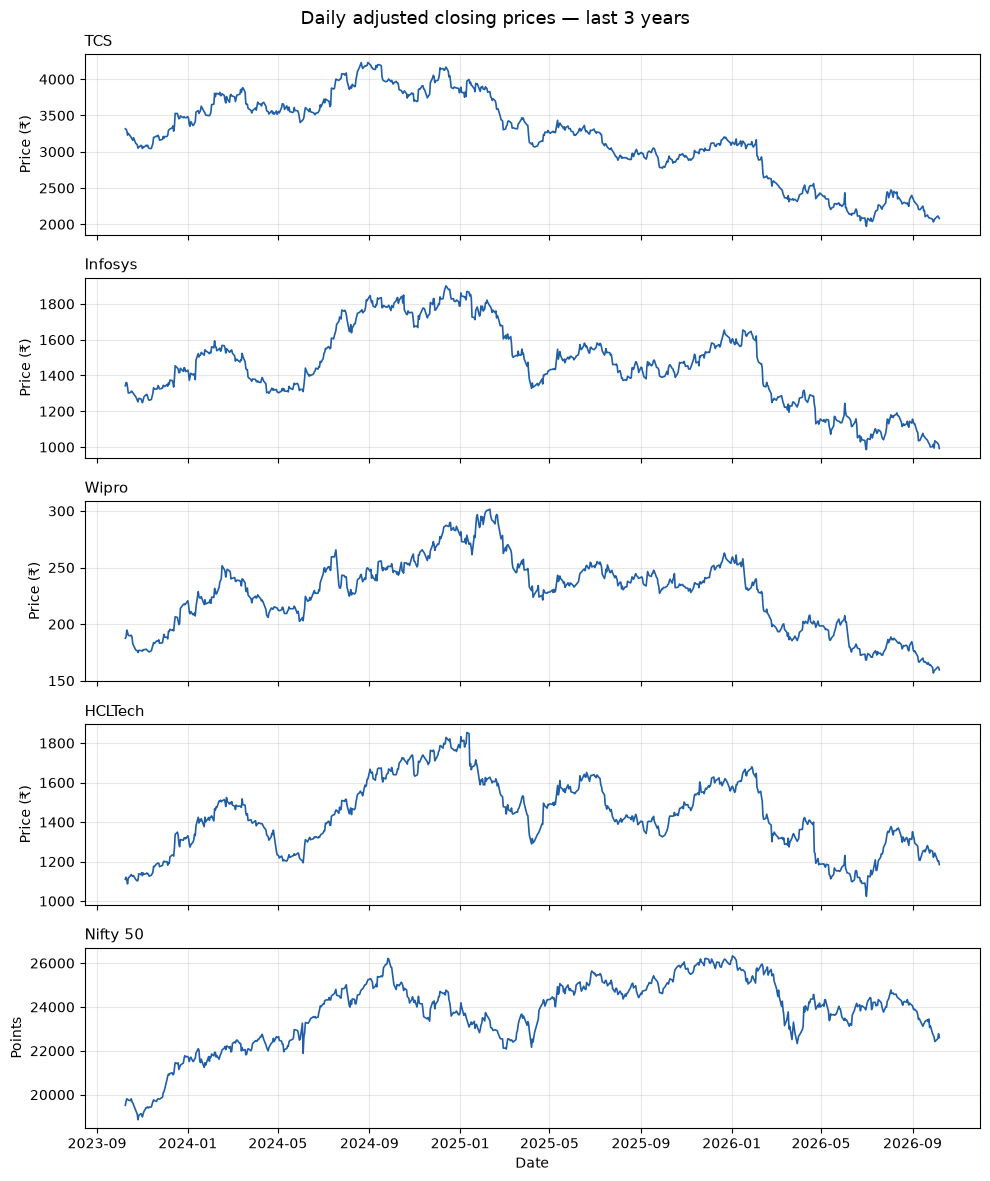

In [8]:
os.makedirs("charts", exist_ok=True)

# 5 charts stacked vertically, sharing the same date axis
fig, axes = plt.subplots(nrows=len(clean.columns), ncols=1, figsize=(10, 12), sharex=True)

for ax, name in zip(axes, clean.columns):
    ax.plot(clean.index, clean[name], color="#1f5fa8", linewidth=1.2)
    ax.set_title(name, loc="left", fontsize=11)
    ax.set_ylabel("Points" if name == "Nifty 50" else "Price (₹)")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")
fig.suptitle("Daily adjusted closing prices — last 3 years", fontsize=13)
fig.tight_layout()

fig.savefig("charts/price_history.png", dpi=150)
plt.show()